# PathSnap | Training, model selection and route reconstruction

**Review walkthrough:** Show sections 1–4 for the dataset, preprocessing, model choice and current inference. Then show section 5 for training commands and saved fold and Optuna outputs.

**Run in Colab:** Open this notebook and upload `PathSnap_Reviewed_Final.zip` into the Files panel so it is at `/content/PathSnap_Reviewed_Final.zip`. Run sections 1–4 for a quick walkthrough. Section 5 rebuilds training features, fits five model families across 16 splits each, runs 18 Optuna trials and refits the release scorer. Allow extra time and save the notebook after running those cells to retain your own logs. The bundled ZIP contains the raw student data. No separate CSV upload is needed.

The saved outputs were executed locally. The evaluator rows in the comparison figure come from the recorded local API checks. This notebook runs inference on student-test trips only.

## 1. Inspect the files and the fitted release

Each trip has a GPS track (longitude, latitude, timestamp), road nodes, directed arcs and a reference route. Trip IDs are strings. The original zero-based arc IDs and directions are preserved. The reference is an ordered arc sequence and becomes a proxy label through alignment. The deployed scorer is a fitted LightGBM LambdaRank ensemble exported to a portable joblib artifact.

In [1]:
import hashlib
import json
import os
import subprocess
import sys
import time
from pathlib import Path
from zipfile import ZipFile

archive = Path('/content/PathSnap_Reviewed_Final.zip')
if Path('/content').is_dir():
    if not archive.is_file():
        raise FileNotFoundError('Upload PathSnap_Reviewed_Final.zip using the Colab Files panel.')
    project = Path('/content/pathsnap_release/pathsnap')
    with ZipFile(archive) as bundle:
        members = [name for name in bundle.namelist() if not name.startswith('pathsnap/.git/')]
        bundle.extractall(project.parent, members)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', 'requirements-training.txt'],
                   cwd=project, check=True)
else:
    project = Path.cwd()

sys.path.insert(0, str(project))
import joblib
import pandas as pd
from IPython.display import display
from pathsnap.core import list_trip_ids

raw = project / 'inputs/Student folder.zip'
review = project / 'results/review'
train_ids = list_trip_ids(raw, 'train')
student_ids = list_trip_ids(raw, 'student_test')
assert len(train_ids) == 80 and len(student_ids) == 10
assert set(train_ids).isdisjoint(student_ids)
artifact = joblib.load(review / 'deployed.joblib')
assert artifact['model'] is not None and artifact['decoder']['restart_penalty'] == 20.
print('Raw dataset SHA256:', hashlib.sha256(raw.read_bytes()).hexdigest())
print(f'{len(train_ids)} training trips and {len(student_ids)} student-test trips')
print('Fitted scorer:', artifact['name'], '| Features:', len(artifact['features']))
print('Decoder settings:', artifact['decoder'])

def run(*args):
    start = time.time()
    print('RUN', sys.executable, *args, flush=True)
    subprocess.run([sys.executable, '-u', *args], cwd=project, check=True,
                   env=os.environ | {'OPENBLAS_NUM_THREADS': '1', 'OMP_NUM_THREADS': '4'})
    print('Elapsed seconds:', round(time.time() - start, 1), flush=True)

Raw dataset SHA256: 4804b0399d1d56f4844b9c74e2f998aae0a281fb5947a1f47ad1bd013214d248
80 training trips and 10 student-test trips
Fitted scorer: LightGBM untuned | Features: 28
Decoder settings: {'emission_weight': 2.0, 'beta_m': 2.6152586684738566, 'max_gap_s': 15.0, 'max_speed_mps': 28.0, 'reversal_penalty': 2.0, 'stationary_speed': 1.0, 'bridge_gaps': True, 'restart_penalty': 20.0}


## 2. Turn GPS points into training examples

Project GPS points onto nearby directed road arcs. The candidate generator searches within 100 m and retains up to eight candidates, with a nearest fallback when needed. For each candidate the features describe proximity, heading, motion and stationarity, reverse directions, road connectivity and trajectory support. The released model uses 28 features and sees the whole trip, including adjacent readings.

Build a training target by aligning the GPS sequence to the ordered reference route. The beam search balances lateral distance against plausible forward movement along the reference. Each point gets an aligned reference arc. Candidate groups without that reference arc cannot teach the ranker to choose it, and evaluation counts those misses. The fitting policy selected candidate-covered observations with a reference snap within 75 m and excluded two training trips with severe alignment anomalies. Evaluation on the full student-test set retains misses.

In [2]:
from pathsnap.candidates import predict_trip
from pathsnap.core import load_reference, load_trip
from pathsnap.ordered_labels import align
from pathsnap.grouped_features import make_candidates
from pathsnap.pipeline import model_trip, reconstruct, metrics
from threadpoolctl import threadpool_limits

trip_id = '00000052'
track, nodes, arcs = load_trip(raw, 'student_test', trip_id)
trip = model_trip(trip_id, track, nodes, arcs)
with threadpool_limits(limits=1):
    observations, candidates = predict_trip(trip, artifact)
reference = load_reference(raw, 'student_test', trip_id)
labels, _, _ = align(trip, reference)
_, features = make_candidates(trip, context=True)
sample_index = int(candidates.groupby('observation_index').size().idxmax())
keys = ['observation_index', 'arc_id']
sample = features.loc[features.observation_index == sample_index,
    keys + ['distance_m', 'smooth_heading_cos', 'trip_arc_support']].merge(
        candidates[keys + ['probability']], on=keys, validate='one_to_one')
sample['matches_aligned_reference'] = sample.arc_id == labels[sample_index]
print(f'Trip {trip_id}: {len(track)} GPS observations and {len(candidates)} scored candidates')
display(sample.sort_values('probability', ascending=False))

Trip 00000052: 262 GPS observations and 2034 scored candidates


,observation_index,arc_id,distance_m,smooth_heading_cos,trip_arc_support,probability,matches_aligned_reference
0,0,1680,6.088593,0.996118,2.079442,0.978614,True
2,0,3033,54.853856,0.997383,0.000000,0.008428,False
6,0,2406,72.867742,0.689647,1.609438,0.002309,False
3,0,1557,69.925893,0.321230,1.386294,0.002304,False
5,0,2401,70.910031,0.232296,1.098612,0.002304,False
4,0,2403,69.925893,0.571735,1.609438,0.002275,False
7,0,2399,73.757472,0.067934,0.000000,0.002179,False
1,0,1033,18.336681,-0.996868,2.079442,0.001588,False


## 3. Explain how LightGBM was selected

**Family comparison.** The initial ordered-label experiment used all 80 training trips, grouped by trip, with eight folds repeated twice. Compare per-observation top-1 and grouped log loss. LambdaRank learns a score for each candidate so the correct arc ranks above other candidates for the same observation. Conditional logit, grouped MLP, ExtraTrees and HistGradientBoosting were also trained. Nearest road and distance plus heading were rule baselines.

**Release configuration.** The later review used richer features and a trusted-label fitting policy. It used 26 training trips for development and 52 for grouped assessment after two exclusions. Optuna TPE searched LightGBM settings over 18 trials. Tuning improved standalone student-test top-1 and covered log loss, while the untuned configuration led the learned methods on decoded assessment CV. The paired comparison with nearest road plus Viterbi was uncertain. The frozen release scorer was refit on the 78 eligible training trips, using 180,365 trusted observations with a reference candidate.

,top1,grouped_log_loss
model,,
Nearest road,49.23%,3.898
Distance + heading,68.84%,3.696
Conditional logit,76.71%,3.479
Grouped MLP,77.28%,3.398
ExtraTrees,77.05%,3.415
LightGBM ranker,78.00%,3.374
HistGradientBoosting,77.77%,3.397


,Trusted decoded CV,Student top-1,Student covered log loss
method,,,
Nearest road,87.55%,52.95%,0.940
LightGBM untuned,87.94%,91.42%,0.257
LightGBM tuned,87.09%,91.74%,0.242
HistGradientBoosting,87.63%,90.44%,0.268


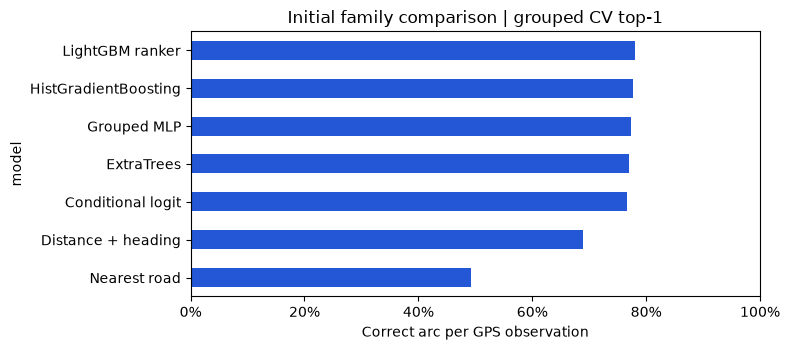

In [3]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

families = pd.read_csv(project / 'results/ordered/cv_summary.csv').set_index('model')
display(families[['top1', 'grouped_log_loss']].style.format({'top1': '{:.2%}', 'grouped_log_loss': '{:.3f}'}))
chosen = ['Nearest road', 'LightGBM untuned', 'LightGBM tuned', 'HistGradientBoosting']
assessment = pd.read_csv(review / 'cv_summary.csv').set_index('method').loc[chosen]
test_previous = pd.read_csv(review / 'test_summary.csv').set_index('method').loc[chosen]
comparison = pd.DataFrame({
    'Trusted decoded CV': assessment.trusted_decoded_top1,
    'Student top-1': test_previous.point_top1,
    'Student covered log loss': test_previous.trusted_covered_log_loss,
})
display(comparison.style.format({'Trusted decoded CV': '{:.2%}', 'Student top-1': '{:.2%}',
                                  'Student covered log loss': '{:.3f}'}))
ax = families.top1.sort_values().plot.barh(figsize=(8, 3.6), color='#2457d6')
ax.set(title='Initial family comparison | grouped CV top-1', xlabel='Correct arc per GPS observation', xlim=(0, 1))
ax.xaxis.set_major_formatter(PercentFormatter(1))
plt.tight_layout()
plt.show()

## 4. Reproduce current student inference and explain trip 00000015

Load the frozen artifact, generate features from the test track and graph, and score every candidate. The classifier-only baseline takes the highest-scoring candidate independently. Viterbi uses the calibrated candidate scores and penalizes mismatches between road travel and GPS displacement, as well as immediate reversals. Directed feasibility and elapsed time constrain the transition. The API reads the reference only after reconstruction to calculate metrics.

**Decoder change.** The earlier decoder could stay on a weakly supported path because it had no option to split while any path was still feasible. The updated recurrence compares normal continuation with starting a new segment from the best prior score, using a fixed cost of 20 log-score units. The current point still gets an arc. Each chosen break records a route event with an empty connector. The same rule applies across trips. The evaluator failure prompted the follow-up, and the penalty was selected by comparing student-test point accuracy across candidate settings. Treat the evaluator rerun as a follow-up result.

**Metrics.** Point accuracy measures the predicted directed arc at each observation against the aligned reference. Direct continuity measures same-arc or connected-endpoint pairs. Ordered route overlap uses the longest common subsequence of arcs and reports F1. These metrics measure different properties.

Live student-test decoded accuracy: 93.17%


,observations,top1,decoded,route_f1
trip_id,,,,
00000000,2503,96.32%,97.08%,94.18%
00000007,1354,96.01%,97.12%,97.98%
00000009,1049,89.04%,90.85%,90.46%
00000040,2995,95.29%,96.26%,97.94%
00000052,262,98.47%,99.24%,98.94%
00000056,3958,91.41%,94.74%,98.46%
00000065,768,92.71%,94.66%,96.35%
00000076,1486,94.62%,95.15%,94.64%
00000077,3911,82.72%,84.51%,78.25%


,Earlier decoder,Updated decoder
Decoded point accuracy,61.28%,92.53%
Ordered route overlap,35.65%,57.63%


Saved evaluator API check: 6,854 points and 316 reported breaks


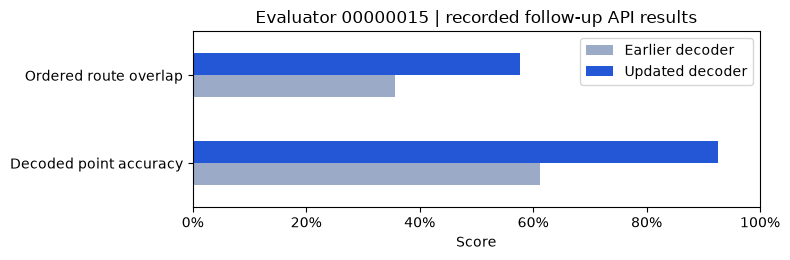

In [4]:
import numpy as np

live_rows = []
with threadpool_limits(limits=1):
    for trip_id in student_ids:
        track, nodes, arcs = load_trip(raw, 'student_test', trip_id)
        trip = model_trip(trip_id, track, nodes, arcs)
        _, candidates = predict_trip(trip, artifact)
        rows = candidates.to_dict('records')
        result = reconstruct(trip_id, track, nodes, arcs, rows, artifact['decoder'])
        reference = load_reference(raw, 'student_test', trip_id)
        scored = metrics(result, trip, rows, reference, ordered=True)
        live_rows.append({'trip_id': trip_id, 'observations': scored['labeled'],
                          'top1': scored['baseline']['point_accuracy'],
                          'decoded': scored['decoded']['point_accuracy'],
                          'route_f1': scored['decoded']['sequence_f1']})
live = pd.DataFrame(live_rows).set_index('trip_id')
saved = pd.read_csv(review / 'restart_validation.csv', dtype={'trip_id': str})
student_reference = saved.query("split == 'student_test'").set_index('trip_id').loc[live.index]
np.testing.assert_allclose(live.decoded, student_reference.decoded_point_accuracy_after)
print('Live student-test decoded accuracy:', f'{np.average(live.decoded, weights=live.observations):.2%}')
display(live.style.format({key: '{:.2%}' for key in ['top1', 'decoded', 'route_f1']}))

case = saved.query("split == 'evaluator_test' and trip_id == '00000015'").iloc[0]
columns = ['decoded_point_accuracy', 'route_f1']
change = pd.DataFrame({'Earlier decoder': [case[k + '_before'] for k in columns],
                       'Updated decoder': [case[k + '_after'] for k in columns]},
                      index=['Decoded point accuracy', 'Ordered route overlap'])
display(change.style.format('{:.2%}'))
print(f"Saved evaluator API check: {int(case.observations):,} points and {int(case.route_breaks_after)} reported breaks")
ax = change.plot.barh(figsize=(8, 2.7), color=['#9aaac7', '#2457d6'])
ax.set(title='Evaluator 00000015 | recorded follow-up API results', xlabel='Score', xlim=(0, 1))
ax.xaxis.set_major_formatter(PercentFormatter(1))
plt.tight_layout()
plt.show()

## 5. Rerun training and export the current decoder configuration

The next three cells retain saved outputs from the original local training run. Rerunning them rebuilds the prepared arrays if needed, trains five models across 16 folds each, and runs 18 Optuna trials. The final cell includes a fresh local export log. It refits the release model from the prepared context features using the recorded assessment CV decision. It writes into a separate folder to preserve the bundled release. The new scorer is paired with the segment restart cost tested above. For the full historical assessment protocol, run `python -m pathsnap.review_experiment RAW_ZIP PREPARED_CONTEXT OUTPUT --phase evaluate`.

When presenting, open the five-model output for fold logs and the Optuna output for trial values. Show the fitted artifact check and the live student-test results in sections 1 and 4.

In [5]:
# Reuse a verified local feature cache if present; on Colab prepare from raw trip files.
local_cache = project.parent.parent / 'work/grouped'
prepared = local_cache if len(list((local_cache / 'train').glob('*.npz'))) == 80 else project / 'work/proof-prepared'
if len(list((prepared / 'train').glob('*.npz'))) != 80:
    run('-m', 'pathsnap.prepare_grouped', str(raw), str(prepared))
assert len(list((prepared / 'train').glob('*.npz'))) == 80
print('Prepared feature source:', prepared)
print('Cache trip files:', len(list((prepared / 'train').glob('*.npz'))))

Prepared feature source: /Users/ayushpaithankar/Documents/Codex/2026-11-18/what/work/grouped
Cache trip files: 80


In [6]:
# Every model is fitted 16 times: two repeats of eight whole-trip folds.
five_out = project / 'results/notebook_proof/five_model'
run('-m', 'pathsnap.grouped_training', str(prepared), str(five_out),
    '--mode', 'compare', '--names', 'Conditional logit', 'Grouped MLP',
    'ExtraTrees', 'LightGBM ranker', 'HistGradientBoosting', '--repeats', '2')
frames = [pd.read_csv(p) for p in sorted(five_out.glob('folds_*.csv'))]
assert len(frames) == 5 and all(len(f) == 16 for f in frames)
five_summary = pd.concat(frames).groupby('model')[['top1','grouped_log_loss']].agg(['mean','std'])
print('FRESH five-model grouped-CV comparison')
display(five_summary)

RUN /Users/ayushpaithankar/Documents/Codex/2026-11-18/what/outputs/pathsnap/.venv/bin/python -m pathsnap.grouped_training /Users/ayushpaithankar/Documents/Codex/2026-11-18/what/work/grouped /Users/ayushpaithankar/Documents/Codex/2026-11-18/what/outputs/pathsnap/results/notebook_proof/five_model --mode compare --names Conditional logit Grouped MLP ExtraTrees LightGBM ranker HistGradientBoosting --repeats 2


Conditional logit 1 1 top1=0.8299, nll=0.7263
Conditional logit 1 2 top1=0.8733, nll=0.5610
Conditional logit 1 3 top1=0.2768, nll=18.2650
Conditional logit 1 4 top1=0.8803, nll=0.5261
Conditional logit 1 5 top1=0.8781, nll=0.5195
Conditional logit 1 6 top1=0.7838, nll=1.7674
Conditional logit 1 7 top1=0.7531, nll=4.5457
Conditional logit 1 8 top1=0.8590, nll=0.9594
Conditional logit 2 1 top1=0.2961, nll=18.2095
Conditional logit 2 2 top1=0.8454, nll=0.5626
Conditional logit 2 3 top1=0.8364, nll=0.8102
Conditional logit 2 4 top1=0.8905, nll=0.5379
Conditional logit 2 5 top1=0.8995, nll=0.4807
Conditional logit 2 6 top1=0.8934, nll=0.8546
Conditional logit 2 7 top1=0.7751, nll=1.5257
Conditional logit 2 8 top1=0.7023, nll=4.7775
Grouped MLP 1 1 top1=0.8315, nll=0.6380
Grouped MLP 1 2 top1=0.8663, nll=0.5044
Grouped MLP 1 3 top1=0.2784, nll=18.2283
Grouped MLP 1 4 top1=0.8907, nll=0.4247
Grouped MLP 1 5 top1=0.8801, nll=0.4388
Grouped MLP 1 6 top1=0.7927, nll=1.6652
Grouped MLP 1 7 top1=

Exit: 0 Elapsed seconds: 322.9


FRESH five-model grouped-CV comparison


top1           grouped_log_loss          
                          mean       std             mean       std
model                                                              
Conditional logit     0.767067  0.195870         3.478572  5.916907
ExtraTrees            0.770490  0.196080         3.415047  5.922460
Grouped MLP           0.772757  0.195851         3.398405  5.931993
HistGradientBoosting  0.778848  0.199025         3.379941  5.931151
LightGBM ranker       0.779951  0.197694         3.373658  5.931969

In [7]:
# Bayesian hyperparameter search for the LightGBM ranking family.
local_context = project.parent.parent / 'work/review-data'
context = local_context if len(list((local_context / 'train').glob('*.npz'))) == 80 else project / 'work/proof-context'
if len(list((context / 'train').glob('*.npz'))) != 80:
    run('-m', 'pathsnap.prepare_grouped', str(raw), str(context), '--context')
ranker_out = project / 'results/notebook_proof/ranker'
run('-m', 'pathsnap.review_experiment', str(raw), str(context), str(ranker_out),
    '--phase', 'ranker', '--trials', '18')
trials = pd.read_csv(ranker_out / 'ranker_optuna_trials.csv')
assert len(trials) == 18
print('Best TPE parameters:', json.loads((ranker_out / 'ranker_parameters.json').read_text()))
display(trials[['number','value','state','params_n_estimators','params_num_leaves','params_max_depth']])

RUN /Users/ayushpaithankar/Documents/Codex/2026-11-18/what/outputs/pathsnap/.venv/bin/python -m pathsnap.review_experiment /Users/ayushpaithankar/Documents/Codex/2026-11-18/what/outputs/pathsnap/inputs/Student folder.zip /Users/ayushpaithankar/Documents/Codex/2026-11-18/what/work/review-data /Users/ayushpaithankar/Documents/Codex/2026-11-18/what/outputs/pathsnap/results/notebook_proof/ranker --phase ranker --trials 18


[I 2026-11-18 16:18:36,805] A new study created in memory with name: no-name-10e5af7c-8ace-43cf-baeb-d301b744d883
[I 2026-11-18 16:18:39,305] Trial 0 finished with value: 0.28185752712518414 and parameters: {'n_estimators': 90, 'num_leaves': 32, 'max_depth': 10, 'learning_rate': 0.08, 'min_child_samples': 40, 'reg_lambda': 0.01}. Best is trial 0 with value: 0.28185752712518414.
[I 2026-11-18 16:18:42,033] Trial 1 finished with value: 0.27588867665598266 and parameters: {'n_estimators': 80, 'num_leaves': 56, 'max_depth': 9, 'learning_rate': 0.07307803426594507, 'min_child_samples': 39, 'reg_lambda': 0.028370443831258373}. Best is trial 1 with value: 0.27588867665598266.
[I 2026-11-18 16:18:43,689] Trial 2 finished with value: 0.282118366665983 and parameters: {'n_estimators': 40, 'num_leaves': 52, 'max_depth': 8, 'learning_rate': 0.08890528335198394, 'min_child_samples': 26, 'reg_lambda': 6.542377205836589}. Best is trial 1 with value: 0.27588867665598266.
[I 2026-11-18 16:18:46,811] Tr

Exit: 0 Elapsed seconds: 48.0


Best TPE parameters: {'n_estimators': 110, 'num_leaves': 20, 'max_depth': 4, 'learning_rate': 0.13687258703610514, 'min_child_samples': 117, 'reg_lambda': 2.2225433823808736}


,number,value,state,params_n_estimators,params_num_leaves,params_max_depth
0,0,0.281858,COMPLETE,90,32,10
1,1,0.275889,COMPLETE,80,56,9
2,2,0.282118,COMPLETE,40,52,8
3,3,0.278161,COMPLETE,130,20,5
4,4,0.295834,COMPLETE,90,24,8
5,5,0.268281,COMPLETE,90,48,5
6,6,0.263377,COMPLETE,110,20,4
7,7,0.286661,COMPLETE,70,16,8
8,8,0.282673,COMPLETE,40,52,5
9,9,0.279284,COMPLETE,100,20,10


In [8]:
import json
import shutil

refit = project / 'work/colab-release'
shutil.copytree(review, refit, dirs_exist_ok=True)
run('-m', 'pathsnap.reselect_release', str(context), str(refit), '--restart-penalty', '20')
new_artifact = joblib.load(refit / 'deployed.joblib')
assert new_artifact['model'] is not None
assert new_artifact['decoder']['restart_penalty'] == 20.
print('Fresh export:', new_artifact['name'], refit / 'deployed.joblib')

RUN /Users/ayushpaithankar/Documents/Codex/2026-11-18/what/outputs/pathsnap/.venv/bin/python -m pathsnap.reselect_release /Users/ayushpaithankar/Documents/Codex/2026-11-18/what/work/review-data /Users/ayushpaithankar/Documents/Codex/2026-11-18/what/outputs/pathsnap/work/colab-release --restart-penalty 20


CV-selected learned method: LightGBM untuned


{
  "selected": "LightGBM untuned",
  "trusted_cv_ranker_vs_nearest": {
    "delta": -0.004525337739656074,
    "low": -0.007298947839741666,
    "high": -0.0015297568471147381,
    "wins": 14,
    "losses": 36,
    "ties": 2
  },
  "transition_beta_m": 2.6152586684738566,
  "model_fit_trips": 78,
  "trusted_fit_observations": 180365,
  "selection_policy": "highest trusted decoded assessment CV accuracy among trained models; rules remain baselines",
  "trusted_cv_selected_vs_nearest": {
    "delta": 0.003969011815698355,
    "low": -0.0019373421712256538,
    "high": 0.012060588704532386,
    "wins": 17,
    "losses": 33,
    "ties": 2
  },
  "trusted_cv_tuned_vs_untuned": {
    "delta": -0.008494349555354429,
    "low": -0.017135542323506715,
    "high": -0.0022377906781469296,
    "wins": 22,
    "losses": 29,
    "ties": 1
  }
}


Elapsed seconds: 5.6


Fresh export: LightGBM untuned /Users/ayushpaithankar/Documents/Codex/2026-11-18/what/outputs/pathsnap/work/colab-release/deployed.joblib
